# TCN Base Model — Delhi Air Quality Forecasting (Anand Vihar)

**Purpose:** Train a Temporal Convolutional Network (TCN) to forecast the next 24 hours of all 11 pollutant measurements from the previous 24 hours.

| Setting | Value |
|---|---|
| Dataset | Combined Anand Vihar 2025 + Jan–Aug 2026 hourly data |
| Inputs | 24 historical hours × 11 pollutants |
| Outputs | 24 future hours × 11 pollutants |
| Split | Chronological 70% train / 15% validation / 15% test |
| Scaling | `RobustScaler`, fitted on training data only |
| Missing inputs | Imputed with training-period pollutant medians |
| Missing targets | Excluded from loss and evaluation using a mask |
| Framework | PyTorch (Google Colab) |

**Important evaluation convention:** this notebook evaluates rolling forecast origins. Every test forecast predicts a 24-hour block entirely inside the test period, using the 24 hours immediately before that forecast origin as historical input. This permits the most recent *observed* readings to be used as the forecast origin advances, which is a realistic hourly-updated forecasting setup. No target from a validation or test forecast window is used as its input.

**Before running:** In Colab, choose **Runtime → Change runtime type → T4 GPU** (or another available GPU). Upload the combined CSV linked with this notebook, not the two source files separately.

## 1. Install / import libraries

In [ ]:
# Colab already includes PyTorch in most runtimes. Install only the data/plotting packages if needed.
%pip -q install numpy pandas scikit-learn matplotlib

import os, glob, json, time, copy, random, zipfile, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: 3.13.16
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


## 2. Reproducibility and experiment configuration

In [ ]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Keep deterministic behaviour where supported. This may reduce speed slightly.
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

TIMESTAMP_COL = "Timestamp"
FEATURES = [
    "PM2.5 (µg/m³)", "PM10 (µg/m³)", "NO (µg/m³)", "NO2 (µg/m³)",
    "NOx (ppb)", "NH3 (µg/m³)", "SO2 (µg/m³)", "CO (mg/m³)",
    "Ozone (µg/m³)", "Benzene (µg/m³)", "Toluene (µg/m³)"
]

SEQ_LEN = 24
HORIZON = 24
TRAIN_FRACTION = 0.70
VAL_FRACTION = 0.15
BATCH_SIZE = 64
MAX_EPOCHS = 40
PATIENCE = 8
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5
GRAD_CLIP_NORM = 1.0

# TCN architecture. With two causal convolutions per block and dilations 1,2,4,8,
# receptive field = 1 + 2*(kernel_size-1)*(1+2+4+8) = 61 time steps.
TCN_CHANNELS = [64, 64, 64, 64]
KERNEL_SIZE = 3
DROPOUT = 0.10

print("Device:", DEVICE)
print("Input shape per sample:", (SEQ_LEN, len(FEATURES)))
print("Output shape per sample:", (HORIZON, len(FEATURES)))

Device: cuda
Input shape per sample: (24, 11)
Output shape per sample: (24, 11)


## 3. Upload and load the combined dataset

In [ ]:
EXPECTED_FILE = "Delhi_AnandVihar_2025_Aug2026_11pollutants_combined_unimputed.csv"
CSV_PATH = ""  # Optional: set this to a file path if the CSV is already in the runtime.

if not CSV_PATH:
    try:
        from google.colab import files
        print("Upload the combined CSV file:")
        uploaded = files.upload()
        csv_candidates = [name for name in uploaded.keys() if name.lower().endswith(".csv")]
        if EXPECTED_FILE in csv_candidates:
            CSV_PATH = EXPECTED_FILE
        elif len(csv_candidates) == 1:
            CSV_PATH = csv_candidates[0]
        else:
            raise ValueError(
                "Please upload exactly the combined 11-pollutant CSV. "
                f"CSV files received: {csv_candidates}"
            )
    except ImportError:
        candidates = glob.glob("*.csv") + glob.glob("/mnt/data/*.csv")
        preferred = [p for p in candidates if Path(p).name == EXPECTED_FILE]
        if preferred:
            CSV_PATH = preferred[0]
        elif len(candidates) == 1:
            CSV_PATH = candidates[0]
        else:
            raise FileNotFoundError(
                "Set CSV_PATH to the combined CSV location. Candidates found: " + str(candidates)
            )

print("Using:", CSV_PATH)
df = pd.read_csv(CSV_PATH)
if TIMESTAMP_COL not in df.columns:
    raise ValueError(f"Missing required timestamp column: {TIMESTAMP_COL}")
missing_features = [c for c in FEATURES if c not in df.columns]
if missing_features:
    raise ValueError(f"Required pollutant columns are missing: {missing_features}")

# Keep only timestamp + the agreed 11 pollutant features, and sort chronologically.
df = df[[TIMESTAMP_COL] + FEATURES].copy()
df[TIMESTAMP_COL] = pd.to_datetime(df[TIMESTAMP_COL], errors="raise")
df = df.sort_values(TIMESTAMP_COL).reset_index(drop=True)

if df[TIMESTAMP_COL].duplicated().any():
    dupes = df.loc[df[TIMESTAMP_COL].duplicated(keep=False), TIMESTAMP_COL]
    raise ValueError(f"Duplicate timestamps found. Resolve them before sequence creation.\n{dupes.head()}")

time_deltas = df[TIMESTAMP_COL].diff().dropna()
non_hourly = time_deltas.ne(pd.Timedelta(hours=1))
if non_hourly.any():
    examples = df.loc[non_hourly[non_hourly].index, TIMESTAMP_COL].head(10).tolist()
    raise ValueError(
        "The series is not strictly hourly. Do not silently compress time gaps. "
        f"Example timestamps after a non-hourly gap: {examples}"
    )

# Convert pollutant values to numeric. Unparseable cells become missing values.
for col in FEATURES:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Shape:", df.shape)
print("First timestamp:", df[TIMESTAMP_COL].min())
print("Last timestamp:", df[TIMESTAMP_COL].max())
print("Duplicate timestamps:", int(df[TIMESTAMP_COL].duplicated().sum()))
display(df.head())

Upload the combined CSV file:


Saving Delhi_AnandVihar_2025_Aug2026_11pollutants_combined_unimputed.csv to Delhi_AnandVihar_2025_Aug2026_11pollutants_combined_unimputed (1).csv
Using: Delhi_AnandVihar_2025_Aug2026_11pollutants_combined_unimputed (1).csv
Shape: (14592, 12)
First timestamp: 2025-01-01 00:00:00
Last timestamp: 2026-08-31 23:00:00
Duplicate timestamps: 0


,Timestamp,PM2.5 (µg/m³),PM10 (µg/m³),NO (µg/m³),NO2 (µg/m³),NOx (ppb),NH3 (µg/m³),SO2 (µg/m³),CO (mg/m³),Ozone (µg/m³),Benzene (µg/m³),Toluene (µg/m³)
0,2025-01-01 00:00:00,251.0,374.0,102.03,58.83,114.27,74.83,13.20,2.81,1.93,6.23,46.30
1,2025-01-01 01:00:00,269.0,437.0,102.10,61.60,115.80,74.32,12.35,2.74,3.05,6.25,45.60
2,2025-01-01 02:00:00,238.0,326.0,59.90,63.22,82.35,81.50,14.50,2.38,4.08,5.72,42.88
3,2025-01-01 03:00:00,227.0,324.0,44.08,61.25,68.40,70.03,16.45,2.00,2.50,6.00,38.80
4,2025-01-01 04:00:00,286.0,381.0,31.90,51.35,53.25,66.12,15.75,1.81,2.55,5.72,36.35


## 4. Quick data-quality report

In [ ]:
missing_report = pd.DataFrame({
    "missing_count": df[FEATURES].isna().sum(),
    "missing_percent": (df[FEATURES].isna().mean() * 100).round(2),
    "observed_count": df[FEATURES].notna().sum(),
})
display(missing_report)

complete_rows = int(df[FEATURES].notna().all(axis=1).sum())
print(f"Rows with all 11 pollutants observed: {complete_rows:,} / {len(df):,}")

# This is a diagnostic only. No values are automatically deleted or clipped.
print("\nTraining will preserve genuine high readings and mask missing targets.")
print("Investigate physically implausible sensor values against the original CPCB source separately.")

,missing_count,missing_percent,observed_count
PM2.5 (µg/m³),941,6.45,13651
PM10 (µg/m³),961,6.59,13631
NO (µg/m³),893,6.12,13699
NO2 (µg/m³),734,5.03,13858
NOx (ppb),716,4.91,13876
NH3 (µg/m³),681,4.67,13911
SO2 (µg/m³),1312,8.99,13280
CO (mg/m³),715,4.90,13877
Ozone (µg/m³),986,6.76,13606
Benzene (µg/m³),873,5.98,13719


Rows with all 11 pollutants observed: 11,553 / 14,592

Training will preserve genuine high readings and mask missing targets.
Investigate physically implausible sensor values against the original CPCB source separately.


## 5. Chronological train / validation / test split

In [ ]:
N = len(df)
train_end = int(N * TRAIN_FRACTION)
val_end = int(N * (TRAIN_FRACTION + VAL_FRACTION))

# Split indices refer to row boundaries. Samples are constructed so that each target
# forecast block lies completely inside its own split. Historical context may look
# backwards across a boundary (e.g., the first validation input uses the final 24
# training hours), which is allowed because those readings are already historical.
train_start_time = df[TIMESTAMP_COL].iloc[0]
train_last_time = df[TIMESTAMP_COL].iloc[train_end - 1]
val_start_time = df[TIMESTAMP_COL].iloc[train_end]
val_last_time = df[TIMESTAMP_COL].iloc[val_end - 1]
test_start_time = df[TIMESTAMP_COL].iloc[val_end]
test_last_time = df[TIMESTAMP_COL].iloc[-1]

print(f"Total rows: {N:,}")
print(f"Train rows: {train_end:,} | {train_start_time} → {train_last_time}")
print(f"Validation rows: {val_end-train_end:,} | {val_start_time} → {val_last_time}")
print(f"Test rows: {N-val_end:,} | {test_start_time} → {test_last_time}")

assert train_end > SEQ_LEN + HORIZON
assert val_end - train_end >= HORIZON
assert N - val_end >= HORIZON

Total rows: 14,592
Train rows: 10,214 | 2025-01-01 00:00:00 → 2026-03-02 13:00:00
Validation rows: 2,189 | 2026-03-02 14:00:00 → 2026-06-01 18:00:00
Test rows: 2,189 | 2026-06-01 19:00:00 → 2026-08-31 23:00:00


## 6. Fit preprocessing on training data only

In [ ]:
raw_values = df[FEATURES].to_numpy(dtype=np.float64)

# Medians are calculated only from the training period. They are used to fill missing
# historical input values, not to fabricate supervised target observations.
train_raw = raw_values[:train_end]
train_medians = np.nanmedian(train_raw, axis=0)
if not np.isfinite(train_medians).all():
    bad = [FEATURES[i] for i, v in enumerate(train_medians) if not np.isfinite(v)]
    raise ValueError(f"These features have no valid observations in the training split: {bad}")

input_missing_mask = ~np.isfinite(raw_values)
imputed_values = np.where(input_missing_mask, train_medians.reshape(1, -1), raw_values)

# Robust scaling is selected because pollutant data can be skewed and contain spikes.
# It is fitted on the imputed TRAINING period only. Use this exact preprocessing in
# the PatchTST notebook for a fair model-to-model comparison.
scaler = RobustScaler(quantile_range=(25.0, 75.0))
scaler.fit(imputed_values[:train_end])
scaled_values = scaler.transform(imputed_values).astype(np.float32)

# Targets are scaled with the same train-fitted scaler. Missing target positions are
# ignored via target_observed_mask during loss and metric calculation.
target_observed_mask = np.isfinite(raw_values)

print("Training medians:")
display(pd.Series(train_medians, index=FEATURES, name="training_median"))
print("Scaler center and scale are learned from training rows only.")

Training medians:


,training_median
PM2.5 (µg/m³),88.00
PM10 (µg/m³),237.00
NO (µg/m³),22.11
NO2 (µg/m³),54.72
NOx (ppb),49.00
NH3 (µg/m³),35.00
SO2 (µg/m³),21.75
CO (mg/m³),1.56
Ozone (µg/m³),10.22
Benzene (µg/m³),2.12


Scaler center and scale are learned from training rows only.


## 7. Create sliding 24-hour input / 24-hour target windows

In [ ]:
class AirQualityWindowDataset(Dataset):
    def __init__(self, values, observed_mask, target_starts, seq_len=24, horizon=24):
        self.values = values
        self.observed_mask = observed_mask
        self.target_starts = np.asarray(target_starts, dtype=np.int64)
        self.seq_len = seq_len
        self.horizon = horizon

    def __len__(self):
        return len(self.target_starts)

    def __getitem__(self, idx):
        target_start = int(self.target_starts[idx])
        input_start = target_start - self.seq_len
        x = self.values[input_start:target_start]                 # (24, 11)
        y = self.values[target_start:target_start+self.horizon]   # (24, 11)
        mask = self.observed_mask[target_start:target_start+self.horizon]
        return (
            torch.from_numpy(np.asarray(x, dtype=np.float32)),
            torch.from_numpy(np.asarray(y, dtype=np.float32)),
            torch.from_numpy(np.asarray(mask, dtype=np.bool_)),
        )

# Target starts are constrained so each target block stays inside its partition.
train_target_starts = np.arange(SEQ_LEN, train_end - HORIZON + 1)
val_target_starts = np.arange(train_end, val_end - HORIZON + 1)
test_target_starts = np.arange(val_end, N - HORIZON + 1)

train_dataset = AirQualityWindowDataset(scaled_values, target_observed_mask, train_target_starts, SEQ_LEN, HORIZON)
val_dataset = AirQualityWindowDataset(scaled_values, target_observed_mask, val_target_starts, SEQ_LEN, HORIZON)
test_dataset = AirQualityWindowDataset(scaled_values, target_observed_mask, test_target_starts, SEQ_LEN, HORIZON)

PIN_MEMORY = DEVICE.type == "cuda"
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=PIN_MEMORY)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=PIN_MEMORY)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=PIN_MEMORY)

print(f"Training windows:   {len(train_dataset):,}")
print(f"Validation windows: {len(val_dataset):,}")
print(f"Testing windows:    {len(test_dataset):,}")
print("Tensor shapes (one sample): X =", (SEQ_LEN, len(FEATURES)), ", y =", (HORIZON, len(FEATURES)))

# Every split must have observed future targets; missing entries are masked, not zeros.
for label, starts in [("train", train_target_starts), ("validation", val_target_starts), ("test", test_target_starts)]:
    observed = target_observed_mask[starts[:, None] + np.arange(HORIZON)[None, :]].sum()
    print(f"{label.title()} observed target cells: {observed:,}")

Training windows:   10,167
Validation windows: 2,166
Testing windows:    2,166
Tensor shapes (one sample): X = (24, 11) , y = (24, 11)
Train observed target cells: 2,514,565
Validation observed target cells: 538,482
Test observed target cells: 544,067


## 8. Define the Temporal Convolutional Network

The network uses **causal convolutions** so an output at a time step cannot use later time steps, **dilations** to expand the receptive field, and residual connections to support deeper learning. The final representation at the latest input time is mapped to a 24 × 11 forecast.

In [ ]:
class CausalConv1d(nn.Module):
    """1-D convolution with left-only padding (causal; output length equals input length)."""
    def __init__(self, in_channels, out_channels, kernel_size, dilation=1):
        super().__init__()
        self.left_padding = (kernel_size - 1) * dilation
        self.conv = nn.Conv1d(
            in_channels, out_channels, kernel_size,
            padding=self.left_padding, dilation=dilation
        )

    def forward(self, x):
        x = self.conv(x)
        if self.left_padding > 0:
            x = x[:, :, :-self.left_padding]
        return x


class TCNResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, dilation, dropout):
        super().__init__()
        self.conv1 = CausalConv1d(in_channels, out_channels, kernel_size, dilation)
        self.relu1 = nn.ReLU()
        self.drop1 = nn.Dropout(dropout)
        self.conv2 = CausalConv1d(out_channels, out_channels, kernel_size, dilation)
        self.relu2 = nn.ReLU()
        self.drop2 = nn.Dropout(dropout)
        self.residual = (
            nn.Conv1d(in_channels, out_channels, kernel_size=1)
            if in_channels != out_channels else nn.Identity()
        )
        self.out_relu = nn.ReLU()

    def forward(self, x):
        y = self.drop1(self.relu1(self.conv1(x)))
        y = self.drop2(self.relu2(self.conv2(y)))
        return self.out_relu(y + self.residual(x))


class TCNForecaster(nn.Module):
    def __init__(self, input_size, output_size, horizon, channels=(64, 64, 64, 64),
                 kernel_size=3, dropout=0.10):
        super().__init__()
        blocks = []
        in_ch = input_size
        dilations = [2 ** i for i in range(len(channels))]
        for out_ch, dilation in zip(channels, dilations):
            blocks.append(TCNResidualBlock(in_ch, out_ch, kernel_size, dilation, dropout))
            in_ch = out_ch
        self.network = nn.Sequential(*blocks)
        self.head = nn.Linear(channels[-1], horizon * output_size)
        self.horizon = horizon
        self.output_size = output_size

    def forward(self, x):
        # Input: (batch, time, features) → Conv1d expects (batch, features, time)
        x = x.transpose(1, 2)
        z = self.network(x)
        last_state = z[:, :, -1]
        forecast = self.head(last_state)
        return forecast.view(-1, self.horizon, self.output_size)


model = TCNForecaster(
    input_size=len(FEATURES),
    output_size=len(FEATURES),
    horizon=HORIZON,
    channels=tuple(TCN_CHANNELS),
    kernel_size=KERNEL_SIZE,
    dropout=DROPOUT,
).to(DEVICE)

parameter_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f"Trainable parameters: {parameter_count:,}")

# Shape check before the training run.
xb, yb, mb = next(iter(train_loader))
with torch.no_grad():
    check_output = model(xb[:2].to(DEVICE))
print("Shape check:", tuple(check_output.shape), "(expected: (2, 24, 11))")
assert tuple(check_output.shape) == (2, HORIZON, len(FEATURES))

TCNForecaster(
  (network): Sequential(
    (0): TCNResidualBlock(
      (conv1): CausalConv1d(
        (conv): Conv1d(11, 64, kernel_size=(3,), stride=(1,), padding=(2,))
      )
      (relu1): ReLU()
      (drop1): Dropout(p=0.1, inplace=False)
      (conv2): CausalConv1d(
        (conv): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(2,))
      )
      (relu2): ReLU()
      (drop2): Dropout(p=0.1, inplace=False)
      (residual): Conv1d(11, 64, kernel_size=(1,), stride=(1,))
      (out_relu): ReLU()
    )
    (1): TCNResidualBlock(
      (conv1): CausalConv1d(
        (conv): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(4,), dilation=(2,))
      )
      (relu1): ReLU()
      (drop1): Dropout(p=0.1, inplace=False)
      (conv2): CausalConv1d(
        (conv): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(4,), dilation=(2,))
      )
      (relu2): ReLU()
      (drop2): Dropout(p=0.1, inplace=False)
      (residual): Identity()
      (out_relu): ReLU()
    )
 

## 9. Masked loss and training / validation functions

In [ ]:
def masked_mse_components(predictions, targets, observed_mask):
    """Return squared-error sum and valid-cell count; missing targets contribute nothing."""
    mask = observed_mask.to(dtype=predictions.dtype)
    squared_error = (predictions - targets).pow(2) * mask
    return squared_error.sum(), mask.sum()


@torch.no_grad()
def evaluate_loss(model, loader):
    model.eval()
    total_squared_error = 0.0
    total_observed = 0.0
    for xb, yb, mb in loader:
        xb = xb.to(DEVICE, non_blocking=True)
        yb = yb.to(DEVICE, non_blocking=True)
        mb = mb.to(DEVICE, non_blocking=True)
        predictions = model(xb)
        err_sum, count = masked_mse_components(predictions, yb, mb)
        total_squared_error += err_sum.item()
        total_observed += count.item()
    if total_observed == 0:
        raise RuntimeError("No observed target values were available for evaluation.")
    return total_squared_error / total_observed


def sync_device():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=3, min_lr=1e-5
)

history = {"epoch": [], "train_masked_mse": [], "val_masked_mse": [], "learning_rate": []}
best_val_loss = float("inf")
best_state = None
epochs_without_improvement = 0

if DEVICE.type == "cuda":
    torch.cuda.reset_peak_memory_stats(DEVICE)
sync_device()
training_start = time.perf_counter()

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    train_squared_error = 0.0
    train_observed = 0.0

    for xb, yb, mb in train_loader:
        xb = xb.to(DEVICE, non_blocking=True)
        yb = yb.to(DEVICE, non_blocking=True)
        mb = mb.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        predictions = model(xb)
        err_sum, observed_count = masked_mse_components(predictions, yb, mb)
        loss = err_sum / observed_count.clamp_min(1.0)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
        optimizer.step()

        train_squared_error += err_sum.detach().item()
        train_observed += observed_count.detach().item()

    train_loss = train_squared_error / max(train_observed, 1.0)
    val_loss = evaluate_loss(model, val_loader)
    scheduler.step(val_loss)
    current_lr = optimizer.param_groups[0]["lr"]

    history["epoch"].append(epoch)
    history["train_masked_mse"].append(train_loss)
    history["val_masked_mse"].append(val_loss)
    history["learning_rate"].append(current_lr)

    print(f"Epoch {epoch:02d}/{MAX_EPOCHS} | train masked MSE: {train_loss:.5f} | "
          f"val masked MSE: {val_loss:.5f} | lr: {current_lr:.2e}")

    if val_loss < best_val_loss - 1e-6:
        best_val_loss = val_loss
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping: no validation improvement for {PATIENCE} epochs.")
        break

sync_device()
training_seconds = time.perf_counter() - training_start
if best_state is None:
    raise RuntimeError("Training did not produce a valid checkpoint.")
model.load_state_dict(best_state)
model.eval()

print(f"\nTraining time: {training_seconds:.2f} seconds")
print(f"Best validation masked MSE: {best_val_loss:.6f}")
if DEVICE.type == "cuda":
    peak_gpu_memory_mb = torch.cuda.max_memory_allocated(DEVICE) / (1024 ** 2)
else:
    peak_gpu_memory_mb = float("nan")
print("Peak GPU memory (MB):", peak_gpu_memory_mb)

Epoch 01/40 | train masked MSE: 0.95076 | val masked MSE: 0.94024 | lr: 1.00e-03
Epoch 02/40 | train masked MSE: 0.71453 | val masked MSE: 0.88535 | lr: 1.00e-03
Epoch 03/40 | train masked MSE: 0.63731 | val masked MSE: 0.86682 | lr: 1.00e-03
Epoch 04/40 | train masked MSE: 0.58093 | val masked MSE: 0.86839 | lr: 1.00e-03
Epoch 05/40 | train masked MSE: 0.53936 | val masked MSE: 0.90228 | lr: 1.00e-03
Epoch 06/40 | train masked MSE: 0.50319 | val masked MSE: 0.87836 | lr: 1.00e-03
Epoch 07/40 | train masked MSE: 0.47610 | val masked MSE: 0.88488 | lr: 5.00e-04
Epoch 08/40 | train masked MSE: 0.44973 | val masked MSE: 0.87047 | lr: 5.00e-04
Epoch 09/40 | train masked MSE: 0.44116 | val masked MSE: 0.89327 | lr: 5.00e-04
Epoch 10/40 | train masked MSE: 0.42921 | val masked MSE: 0.89194 | lr: 5.00e-04
Epoch 11/40 | train masked MSE: 0.42100 | val masked MSE: 0.89131 | lr: 2.50e-04
Early stopping: no validation improvement for 8 epochs.

Training time: 24.42 seconds
Best validation masked 

## 10. Training curves

,epoch,train_masked_mse,val_masked_mse,learning_rate
6,7,0.476103,0.884878,0.00050
7,8,0.449731,0.870468,0.00050
8,9,0.441157,0.893274,0.00050
9,10,0.429208,0.891939,0.00050
10,11,0.421000,0.891308,0.00025


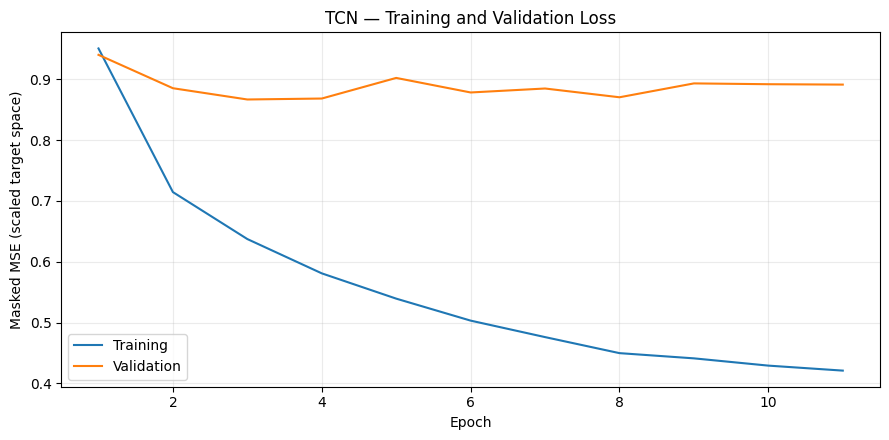

In [ ]:
history_df = pd.DataFrame(history)
display(history_df.tail())

plt.figure(figsize=(9, 4.5))
plt.plot(history_df["epoch"], history_df["train_masked_mse"], label="Training")
plt.plot(history_df["epoch"], history_df["val_masked_mse"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Masked MSE (scaled target space)")
plt.title("TCN — Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("tcn_training_validation_loss.png", dpi=160)
plt.show()

## 11. Generate predictions on the untouched test period

In [ ]:
@torch.no_grad()
def predict_scaled(model, loader):
    model.eval()
    predictions_list, targets_list, masks_list = [], [], []
    for xb, yb, mb in loader:
        xb = xb.to(DEVICE, non_blocking=True)
        predictions = model(xb).cpu().numpy()
        predictions_list.append(predictions)
        targets_list.append(yb.numpy())
        masks_list.append(mb.numpy())
    return (
        np.concatenate(predictions_list, axis=0),
        np.concatenate(targets_list, axis=0),
        np.concatenate(masks_list, axis=0),
    )

pred_scaled, true_scaled, test_mask = predict_scaled(model, test_loader)

# Inverse transform all feature values back to the original measurement units.
num_test_windows = pred_scaled.shape[0]
pred_original = scaler.inverse_transform(pred_scaled.reshape(-1, len(FEATURES))).reshape(
    num_test_windows, HORIZON, len(FEATURES)
)
true_original = scaler.inverse_transform(true_scaled.reshape(-1, len(FEATURES))).reshape(
    num_test_windows, HORIZON, len(FEATURES)
)

print("Prediction tensor:", pred_original.shape)
print("Observed target cells in test forecasts:", int(test_mask.sum()))
assert pred_original.shape == (len(test_dataset), HORIZON, len(FEATURES))

Prediction tensor: (2166, 24, 11)
Observed target cells in test forecasts: 544067


## 12. Test metrics — pollutant-wise and scale-aware summary

The pollutants have different units and numerical ranges (for example, CO is reported in mg/m³ while most others are in µg/m³). Therefore, **do not rank models using one pooled raw-unit MAE across all pollutants**. This section reports MAE, RMSE and R² separately for every pollutant, plus macro-averaged errors normalised by each pollutant's training-period IQR. Use the same definitions for PatchTST and every teammate's models.

In [ ]:
metric_rows = []
for j, feature in enumerate(FEATURES):
    valid = test_mask[:, :, j].astype(bool)
    y_true = true_original[:, :, j][valid]
    y_pred = pred_original[:, :, j][valid]
    if len(y_true) == 0:
        mae = rmse = r2 = np.nan
    else:
        mae = mean_absolute_error(y_true, y_pred)
        rmse = mean_squared_error(y_true, y_pred) ** 0.5
        r2 = r2_score(y_true, y_pred) if len(y_true) >= 2 and np.var(y_true) > 0 else np.nan
    feature_scale = float(scaler.scale_[j])
    metric_rows.append({
        "pollutant": feature,
        "observed_test_targets": int(valid.sum()),
        "MAE_original_units": mae,
        "RMSE_original_units": rmse,
        "R2": r2,
        "normalized_MAE_by_training_IQR": mae / feature_scale if np.isfinite(mae) else np.nan,
        "normalized_RMSE_by_training_IQR": rmse / feature_scale if np.isfinite(rmse) else np.nan,
        "training_IQR_scale": feature_scale,
    })

metrics_df = pd.DataFrame(metric_rows)
display(metrics_df.round(4))

macro_summary = {
    "model": "TCN",
    "test_windows": int(num_test_windows),
    "observed_test_target_cells": int(test_mask.sum()),
    "macro_normalized_MAE_by_training_IQR": float(metrics_df["normalized_MAE_by_training_IQR"].mean()),
    "macro_normalized_RMSE_by_training_IQR": float(metrics_df["normalized_RMSE_by_training_IQR"].mean()),
    "macro_R2": float(metrics_df["R2"].mean()),
    "training_time_seconds": float(training_seconds),
    "trainable_parameters": int(parameter_count),
    "peak_GPU_memory_MB": float(peak_gpu_memory_mb) if np.isfinite(peak_gpu_memory_mb) else None,
}
print("Macro summary (use for the cross-model comparison, alongside pollutant-wise scores):")
display(pd.DataFrame([macro_summary]).round(5))

,pollutant,observed_test_targets,MAE_original_units,RMSE_original_units,R2,normalized_MAE_by_training_IQR,normalized_RMSE_by_training_IQR,training_IQR_scale
0,PM2.5 (µg/m³),48701,28.7196,38.6245,0.1077,0.2374,0.3192,121.0000
1,PM10 (µg/m³),48878,107.6564,155.9739,0.0565,0.5054,0.7323,213.0000
2,NO (µg/m³),49127,16.1387,22.9218,-0.3448,0.3454,0.4906,46.7225
3,NO2 (µg/m³),49751,16.8275,20.9311,-0.0410,0.3860,0.4802,43.5925
4,NOx (ppb),49727,19.5024,26.1649,-0.2504,0.3415,0.4581,57.1150
5,NH3 (µg/m³),49583,7.9773,11.6480,-0.1401,0.2853,0.4165,27.9650
6,SO2 (µg/m³),49656,7.4642,9.7454,-0.2724,0.5194,0.6782,14.3700
7,CO (mg/m³),49055,0.5220,0.6862,0.4036,0.3838,0.5046,1.3600
8,Ozone (µg/m³),49463,6.6711,9.7276,0.5136,0.5510,0.8034,12.1075
9,Benzene (µg/m³),50063,0.8977,1.6075,-0.3538,0.2664,0.4770,3.3700


Macro summary (use for the cross-model comparison, alongside pollutant-wise scores):


,model,test_windows,observed_test_target_cells,macro_normalized_MAE_by_training_IQR,macro_normalized_RMSE_by_training_IQR,macro_R2,training_time_seconds,trainable_parameters,peak_GPU_memory_MB
0,TCN,2166,544067,0.38247,0.52877,-0.16019,24.42029,106568,26.25879


## 13. Error by forecast lead time (1–24 hours ahead)

,forecast_hour,macro_normalized_MAE_by_training_IQR,macro_normalized_RMSE_by_training_IQR
0,1,0.2669,0.3820
1,2,0.3134,0.4419
2,3,0.3445,0.4809
3,4,0.3640,0.5030
4,5,0.3913,0.5317
5,6,0.3876,0.5262
6,7,0.3767,0.5189
7,8,0.3795,0.5218
8,9,0.3754,0.5209
9,10,0.3735,0.5206


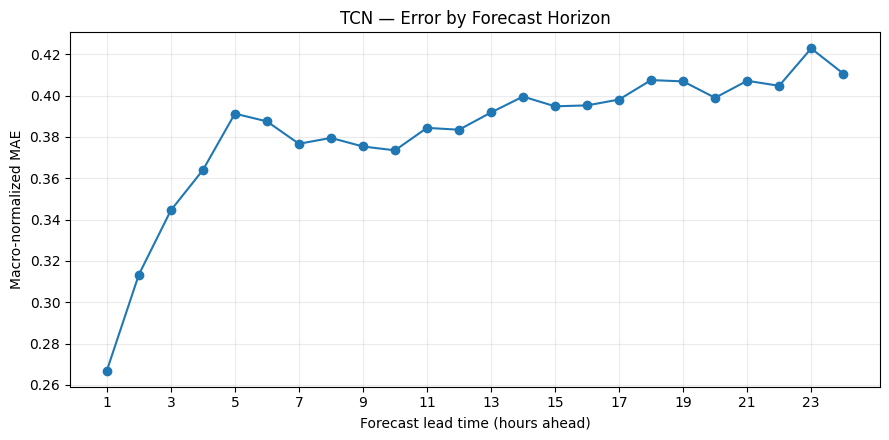

In [ ]:
horizon_rows = []
for h in range(HORIZON):
    per_feature_nmae = []
    per_feature_nrmse = []
    per_feature_mae = []
    for j in range(len(FEATURES)):
        valid = test_mask[:, h, j].astype(bool)
        if valid.sum() == 0:
            continue
        yt = true_original[:, h, j][valid]
        yp = pred_original[:, h, j][valid]
        mae_h = mean_absolute_error(yt, yp)
        rmse_h = mean_squared_error(yt, yp) ** 0.5
        scale_h = float(scaler.scale_[j])
        per_feature_mae.append(mae_h)
        per_feature_nmae.append(mae_h / scale_h)
        per_feature_nrmse.append(rmse_h / scale_h)
    horizon_rows.append({
        "forecast_hour": h + 1,
        "macro_normalized_MAE_by_training_IQR": np.mean(per_feature_nmae) if per_feature_nmae else np.nan,
        "macro_normalized_RMSE_by_training_IQR": np.mean(per_feature_nrmse) if per_feature_nrmse else np.nan,
    })

horizon_metrics_df = pd.DataFrame(horizon_rows)
display(horizon_metrics_df.round(4))

plt.figure(figsize=(9, 4.5))
plt.plot(horizon_metrics_df["forecast_hour"], horizon_metrics_df["macro_normalized_MAE_by_training_IQR"], marker="o")
plt.xlabel("Forecast lead time (hours ahead)")
plt.ylabel("Macro-normalized MAE")
plt.title("TCN — Error by Forecast Horizon")
plt.xticks(range(1, HORIZON + 1, 2))
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("tcn_error_by_forecast_horizon.png", dpi=160)
plt.show()

## 14. Actual vs predicted example — PM2.5

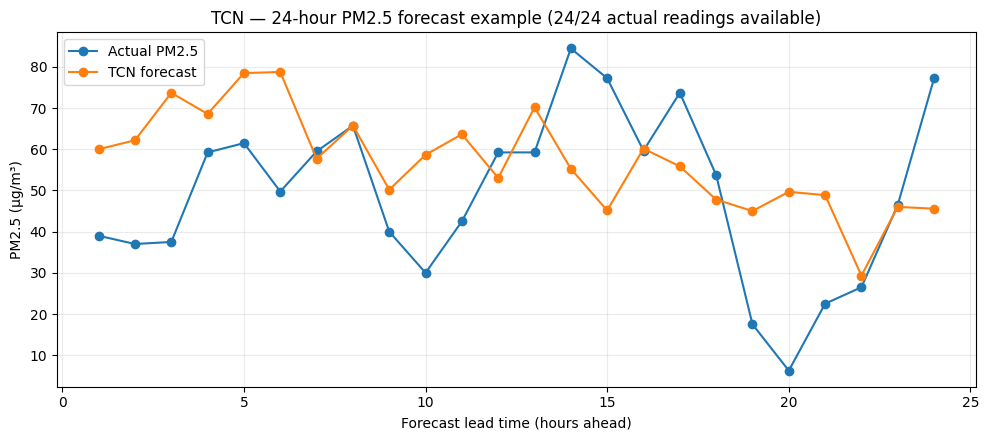

In [ ]:
pm25_idx = FEATURES.index("PM2.5 (µg/m³)")
# Prefer a complete 24-hour PM2.5 target window; otherwise use the window with most observed PM2.5 readings.
pm25_counts = test_mask[:, :, pm25_idx].sum(axis=1)
example_idx = int(np.argmax(pm25_counts))
actual_line = true_original[example_idx, :, pm25_idx].astype(float).copy()
actual_line[~test_mask[example_idx, :, pm25_idx]] = np.nan
pred_line = pred_original[example_idx, :, pm25_idx]

plt.figure(figsize=(10, 4.5))
plt.plot(np.arange(1, HORIZON + 1), actual_line, marker="o", label="Actual PM2.5")
plt.plot(np.arange(1, HORIZON + 1), pred_line, marker="o", label="TCN forecast")
plt.xlabel("Forecast lead time (hours ahead)")
plt.ylabel("PM2.5 (µg/m³)")
plt.title(f"TCN — 24-hour PM2.5 forecast example ({int(pm25_counts[example_idx])}/24 actual readings available)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("tcn_pm25_actual_vs_predicted_example.png", dpi=160)
plt.show()

## 15. Inference speed and model size

In [ ]:
@torch.no_grad()
def benchmark_inference(model, input_shape, batch_size, warmup=10, repetitions=50):
    model.eval()
    x = torch.zeros((batch_size, *input_shape), dtype=torch.float32, device=DEVICE)
    for _ in range(warmup):
        _ = model(x)
    sync_device()
    start = time.perf_counter()
    for _ in range(repetitions):
        _ = model(x)
    sync_device()
    elapsed = time.perf_counter() - start
    ms_per_batch = (elapsed / repetitions) * 1000
    return {
        "batch_size": batch_size,
        "milliseconds_per_batch": ms_per_batch,
        "milliseconds_per_forecast": ms_per_batch / batch_size,
        "forecasts_per_second": 1000 / (ms_per_batch / batch_size),
    }

latency_batch1 = benchmark_inference(model, (SEQ_LEN, len(FEATURES)), batch_size=1)
latency_batch64 = benchmark_inference(model, (SEQ_LEN, len(FEATURES)), batch_size=64)
latency_df = pd.DataFrame([latency_batch1, latency_batch64])
display(latency_df.round(4))

print("Note: inference times depend on the Colab GPU/CPU type. Record the device name with the results.")

,batch_size,milliseconds_per_batch,milliseconds_per_forecast,forecasts_per_second
0,1,2.0129,2.0129,496.7839
1,64,2.1439,0.0335,29852.4892


Note: inference times depend on the Colab GPU/CPU type. Record the device name with the results.


## 16. Save model, metrics, configuration and comparison-ready artifacts

In [ ]:
OUTPUT_DIR = Path("tcn_artifacts")
OUTPUT_DIR.mkdir(exist_ok=True)

# Save the best validation checkpoint, not the final epoch by default.
checkpoint_path = OUTPUT_DIR / "tcn_best_model.pt"
torch.save({
    "model_state_dict": model.state_dict(),
    "feature_names": FEATURES,
    "seq_len": SEQ_LEN,
    "horizon": HORIZON,
    "tcn_channels": TCN_CHANNELS,
    "kernel_size": KERNEL_SIZE,
    "dropout": DROPOUT,
    "scaler_center": scaler.center_.tolist(),
    "scaler_scale": scaler.scale_.tolist(),
    "train_medians": train_medians.tolist(),
    "seed": SEED,
}, checkpoint_path)

checkpoint_size_mb = checkpoint_path.stat().st_size / (1024 ** 2)

metrics_df.to_csv(OUTPUT_DIR / "tcn_test_metrics_by_pollutant.csv", index=False)
horizon_metrics_df.to_csv(OUTPUT_DIR / "tcn_test_metrics_by_forecast_hour.csv", index=False)
history_df.to_csv(OUTPUT_DIR / "tcn_training_history.csv", index=False)
latency_df.to_csv(OUTPUT_DIR / "tcn_inference_benchmark.csv", index=False)

run_config = {
    **macro_summary,
    "model_checkpoint_size_MB": float(checkpoint_size_mb),
    "device": str(DEVICE),
    "gpu_name": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "seed": SEED,
    "features": FEATURES,
    "sequence_length_hours": SEQ_LEN,
    "forecast_horizon_hours": HORIZON,
    "split": {
        "train_fraction": TRAIN_FRACTION,
        "validation_fraction": VAL_FRACTION,
        "train_rows": int(train_end),
        "validation_rows": int(val_end-train_end),
        "test_rows": int(N-val_end),
        "train_start": str(train_start_time),
        "train_end": str(train_last_time),
        "validation_start": str(val_start_time),
        "validation_end": str(val_last_time),
        "test_start": str(test_start_time),
        "test_end": str(test_last_time),
    },
    "preprocessing": "Training-period median imputation for inputs; RobustScaler fit on imputed training period only; missing future targets masked in loss and metrics.",
    "best_validation_masked_mse": float(best_val_loss),
    "inference_benchmark_batch_1": latency_batch1,
    "inference_benchmark_batch_64": latency_batch64,
}
with open(OUTPUT_DIR / "tcn_run_summary.json", "w", encoding="utf-8") as f:
    json.dump(run_config, f, indent=2)

# Copy plots created above into the artifact folder.
for plot_name in [
    "tcn_training_validation_loss.png",
    "tcn_error_by_forecast_horizon.png",
    "tcn_pm25_actual_vs_predicted_example.png",
]:
    if Path(plot_name).exists():
        import shutil
        shutil.copy2(plot_name, OUTPUT_DIR / plot_name)

zip_path = Path("tcn_artifacts.zip")
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for item in OUTPUT_DIR.iterdir():
        zf.write(item, arcname=item.name)

print("Saved checkpoint:", checkpoint_path)
print("Saved comparison tables, run summary and plots in:", OUTPUT_DIR.resolve())
print("Created:", zip_path.resolve())

Saved checkpoint: tcn_artifacts/tcn_best_model.pt
Saved comparison tables, run summary and plots in: /content/tcn_artifacts
Created: /content/tcn_artifacts.zip
